In [12]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
from dataset import CANDatasetEnet as CANDataset
import torch
from torchvision import transforms, datasets
import tqdm
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [14]:
test_dataset = CANDataset(root_dir='../data/size_64_10/TFRecord_w64_s32/2/', window_size=32, is_train=False, is_test=False, include_data=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

In [15]:
len(test_loader.dataset)

26215

In [16]:
classes = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
n_classes = len(classes)

In [28]:
import numpy as np


def plot_embeddings(embeddings, targets, xlim=None, ylim=None, save_dir=None):
    plt.figure(figsize=(12,10))
    for i in range(n_classes):
        inds = np.where(targets==i)[0]
        plt.scatter(embeddings[inds,0], embeddings[inds,1], alpha=0.5, color=colors[i])
    if xlim:
        plt.xlim(xlim[0], xlim[1])
    if ylim:
        plt.ylim(ylim[0], ylim[1])
    plt.legend(classes)

In [21]:
from vit_pytorch.cct import CCT
cct_model = CCT(
        img_size = 64,
        embedding_dim = 128, # the number of filters in the convolutional layers
        n_conv_layers = 2, # number of convolutional layers
        kernel_size = 3,
        stride = 2,
        padding = 1,
        pooling_kernel_size = 3,
        pooling_stride = 1,
        pooling_padding = 1,
        num_layers = 2, # the number of transformer encoder layers
        num_heads = 2, # the number of attention heads in each transformer encoder layer
        mlp_ratio = 1., # dim feedforward layer = embedding_dim * mlp_ratio
        num_classes = 10,
        positional_embedding = 'learnable', # ['sine', 'learnable', 'none']
    )

In [22]:
# model_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_CCT-RetNet_lr_0.0003_decay_0.0001_bsz_64_trial_0_epochs_50/052126_144808/best.pth'
model_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_CCT-RetNet_lr_0.0003_decay_0.0001_bsz_64_trial_0_epochs_100/052126_152828/best.pth'

In [23]:
ckpt = torch.load(model_path, weights_only=False)
state_dict = ckpt['model']
cct_model.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [24]:
import numpy as np
from main_vit import get_predict

total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 
total_embs = np.empty(shape=(0, 128), dtype=float)

cct_model = cct_model.cuda()
cct_model.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)
        outputs = cct_model(images)
        embs = cct_model.forward_features(images) # shape is (batch_size, embedding_dim)
        
        pred = get_predict(outputs)

        embs = embs.cpu().numpy()
        total_embs = np.concatenate((total_embs, embs), axis=0)
        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)

100%|██████████| 410/410 [00:20<00:00, 19.64it/s]


In [25]:
num_samples = 1000
indices = np.empty(shape=(0), dtype=int)
for c in range(n_classes):
    idx_c = np.where(total_label == c)[0]
    if len(idx_c) == 0:
        print(f"Warning: No samples found for class {c}.")
        continue
    idx_c = np.random.choice(idx_c, num_samples, replace=True)
    indices = np.concatenate((indices, idx_c), axis=0)

In [26]:
total_embs[indices] /= 10**2
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
embeddings_scaled = scaler.fit_transform(total_embs[indices])

In [29]:
tsne = TSNE(n_components=2, learning_rate='auto', init='random', n_jobs=-1, perplexity=60)
new_embs = tsne.fit_transform(total_embs[indices])

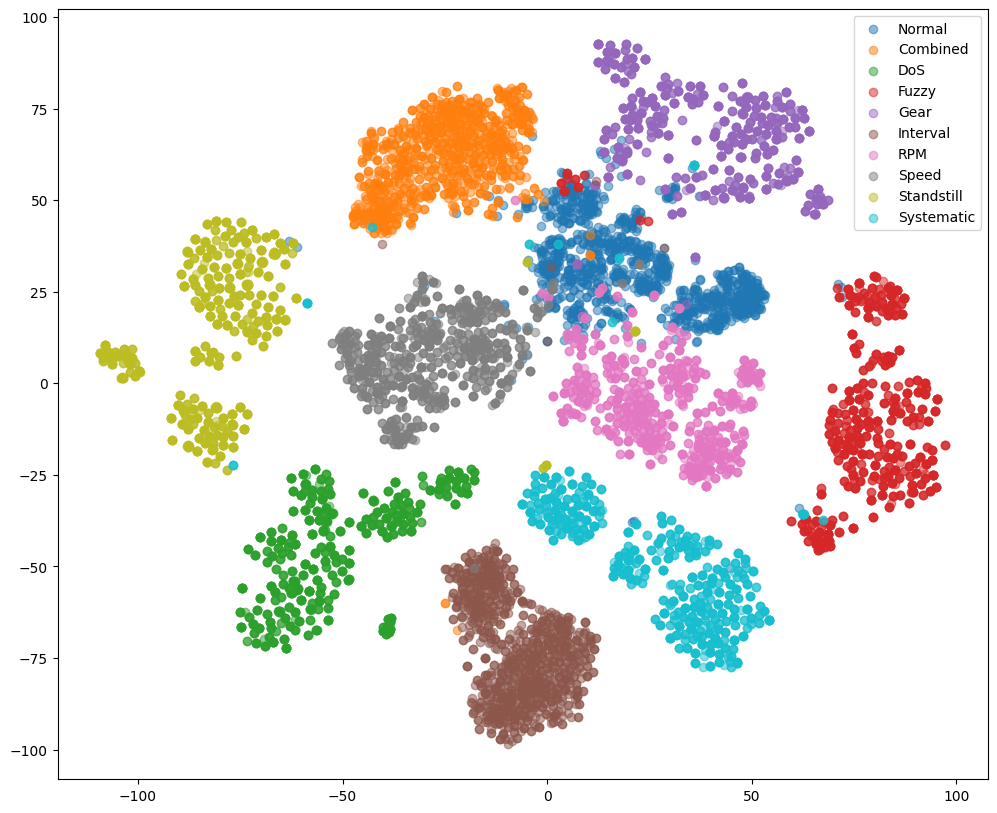

In [30]:
plot_embeddings(new_embs, total_label[indices])
plt.savefig('../images/embedding_space/cct_retnet_80_epochs.png', dpi=300)